# DIMS: український benchmark авторства ELTeC v1

**Висновок:** довші тексти дають кращий сигнал авторства; короткі тексти за строгого порога часто лишаються невиявленими. Cosine краще ранжує пари в цій вибірці. Це дослід відстаней (стилометричної компоненти), а не оцінка інтегрального показника DIMS.

Код прогону: `../tools/authorship_benchmark.py`. Команди відтворення, джерело й обмеження: `README.md`. Notebook показує збережений результат; для повторного обчислення відстаней запустіть CLI з README.

## Контекст і метод

48 одноосібних творів після виключення співавторського роману. Три групи без спільних авторів: еталон, калібрування порога, оцінювання. До трьох неперекривних уривків на твір. Позитивні пари походять із **різних творів** того самого автора.

Поріг: 1-й процентиль відстаней між різними авторами калібрувальної групи, заданий до перегляду результатів. Менша відстань — сигнал близькості. Це не posterior probability і не гарантія 1% хибних спрацювань на нових авторах.

Довжини рахуються до фільтрування. `default` вилучає однолітерні слова, `keep_single` зберігає їх; уривки вирівняні. Найчастотніші слова та нормалізація беруться тільки з еталонної групи.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import NullLocator
from IPython.display import display

DATA = Path("eltec-v1")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
manifest = json.loads((DATA / "manifest.json").read_text())
results = pd.read_csv(DATA / "summary.csv")
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
COLORS = {"burrows": "#205b99", "cosine": "#c45718"}
assert len(results) == 80
assert not results.duplicated(["variant", "raw_words", "mfw", "metric"]).any()
assert np.isfinite(results.select_dtypes("number").to_numpy()).all()
assert results[["true_positive_rate", "false_positive_rate", "roc_auc"]].ge(0).all().all()
assert results[["true_positive_rate", "false_positive_rate", "roc_auc"]].le(1).all().all()
assert np.allclose(results.true_positive_rate, results.true_positives / results.same_author_pairs)
assert np.allclose(results.false_positive_rate, results.false_positives / results.different_author_pairs)
author_sets = [{w["author"] for w in works} for works in manifest["partitions"].values()]
assert all(not x & y for i, x in enumerate(author_sets) for y in author_sets[i + 1:])
print("80 configurations checked; reference/calibration/evaluation authors are disjoint.")

80 configurations checked; reference/calibration/evaluation authors are disjoint.


## Дані та походження

[ELTeC-ukr](https://github.com/COST-ELTeC/ELTeC-ukr), Dmytro Yesypenko та Mykhailo Nazarenko, v0.5.0 (2021), [DOI](https://doi.org/10.5281/zenodo.4662731). CC BY 4.0; тексти завантажуються окремо. Маніфест містить хеші файлів і коду рушія. Історична художня проза не репрезентує сучасні новини чи Telegram.

In [2]:
print("Pinned corpus revision:", manifest["corpus_revision"])
display(pd.DataFrame([{"partition": name, "works": len(works),
                      "authors": len({w["author"] for w in works})}
                     for name, works in manifest["partitions"].items()]))
print("Evaluation authors:")
print("\n".join(sorted({w["author"] for w in manifest["partitions"]["evaluation"]})))
print("Excluded:", manifest["excluded"])

Pinned corpus revision: a8c3d71301cdba767e33551ff0099da1dc51681a


,partition,works,authors
0,reference,13,11
1,calibration,13,12
2,evaluation,22,7


Evaluation authors:
Вовчок, Марко [Марія Вілінська]
Грінченко, Борис
Кащенко, Адріан
Квітка-Основ'яненко, Григорій
Кобилянська, Ольга
Українка, Леся [Лариса Косач]
Франко, Іван
Excluded: [{'id': 'UKR18801', 'reason': 'coauthored by Panas Myrnyi and Ivan Bilyk'}]


## Результати: поточна токенізація, 100 частотних слів

TPR — частка виявлених пар спільного автора; FPR — частка хибних спрацювань між різними авторами. ROC AUC описує ранжування на всіх порогах, а не точність при обраному порозі.

,raw_words,metric,same_author_pairs,different_author_pairs,true_positive_rate,false_positive_rate,roc_auc
0,250,burrows,216,1863,0.0000,0.0005,0.6014
1,250,cosine,216,1863,0.0926,0.0145,0.6651
8,500,burrows,216,1863,0.0093,0.0011,0.6497
9,500,cosine,216,1863,0.1157,0.0145,0.7456
16,1000,burrows,216,1863,0.0556,0.0011,0.7115
17,1000,cosine,216,1863,0.1852,0.0145,0.7936
24,2500,burrows,198,1755,0.1364,0.0028,0.8357
25,2500,cosine,198,1755,0.3384,0.0131,0.8934
32,5000,burrows,156,1388,0.3141,0.0014,0.9249
33,5000,cosine,156,1388,0.5128,0.0108,0.9517


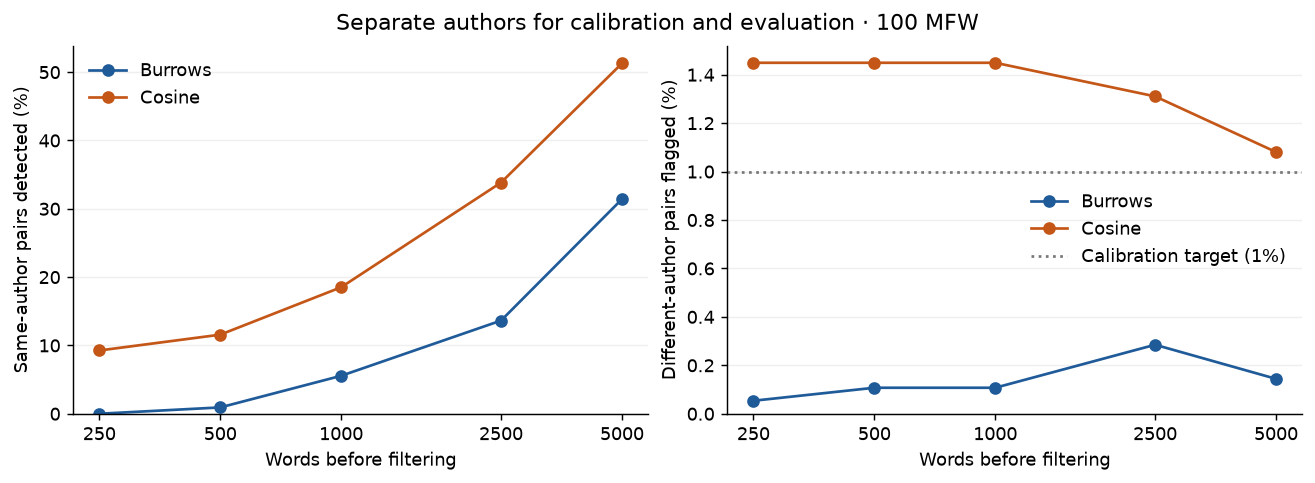

In [3]:
baseline = results.query("variant == 'default' and mfw == 100").sort_values(["raw_words", "metric"])
display(baseline[["raw_words", "metric", "same_author_pairs", "different_author_pairs",
                  "true_positive_rate", "false_positive_rate", "roc_auc"]].round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for metric, color in COLORS.items():
    subset = baseline.query("metric == @metric")
    axes[0].plot(subset.raw_words, subset.true_positive_rate * 100, "o-", color=color, label=metric.title())
    axes[1].plot(subset.raw_words, subset.false_positive_rate * 100, "o-", color=color, label=metric.title())
for ax in axes:
    ax.set_xscale("log")
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xticks([250, 500, 1000, 2500, 5000], labels=[250, 500, 1000, 2500, 5000])
    ax.set_xlabel("Words before filtering")
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=.2)
axes[0].set_ylabel("Same-author pairs detected (%)")
axes[1].set_ylabel("Different-author pairs flagged (%)")
axes[1].axhline(1, linestyle=":", color="#777777", label="Calibration target (1%)")
axes[0].legend(frameon=False)
axes[1].legend(frameon=False)
fig.suptitle("Separate authors for calibration and evaluation · 100 MFW")
fig.savefig(FIGURES / "screening.png", bbox_inches="tight")
plt.show()

Cosine має вищу чутливість, але й іншу фактичну FPR: це не порівняння при однаковій частоті помилок. На 5000 слів залишається лише 156 позитивних пар проти 216 на 500 слів; частина ефекту довжини може залежати від складу доступних уривків.

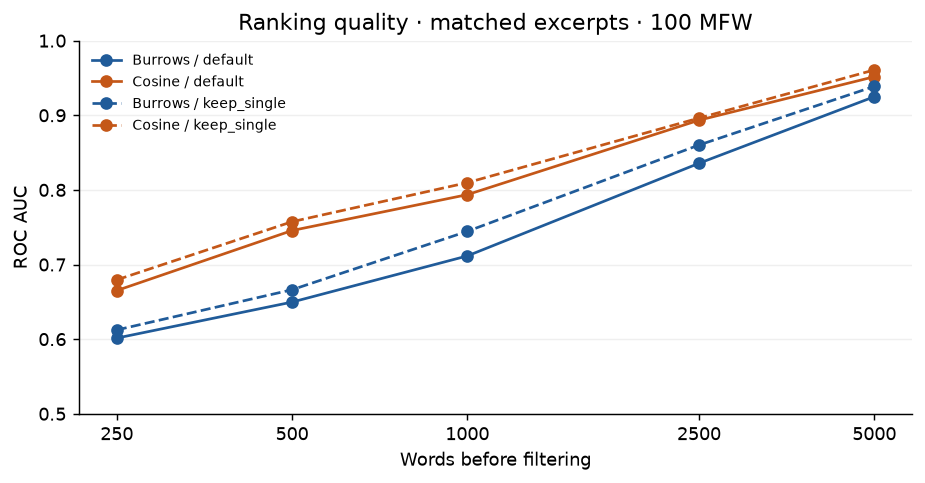

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6), constrained_layout=True)
for variant, style in [("default", "-"), ("keep_single", "--")]:
    for metric, color in COLORS.items():
        subset = results.query("variant == @variant and metric == @metric and mfw == 100").sort_values("raw_words")
        ax.plot(subset.raw_words, subset.roc_auc, marker="o", linestyle=style, color=color,
                label=f"{metric.title()} / {variant}")
ax.set_xscale("log")
ax.xaxis.set_minor_locator(NullLocator())
ax.set_xticks([250, 500, 1000, 2500, 5000], labels=[250, 500, 1000, 2500, 5000])
ax.set_ylim(.5, 1)
ax.set_xlabel("Words before filtering")
ax.set_ylabel("ROC AUC")
ax.set_title("Ranking quality · matched excerpts · 100 MFW")
ax.legend(frameon=False, fontsize=8)
ax.grid(axis="y", alpha=.2)
fig.savefig(FIGURES / "ranking.png", bbox_inches="tight")
plt.show()

## Кількість ознак та вибір варіанта

80 конфігурацій — пошукове порівняння, а не 80 незалежних підтверджень. Вибір переможця за цими даними потребуватиме нової незалежної тестової вибірки.

,variant,mfw,metric,true_positive_rate,false_positive_rate,macro_author_tpr,macro_author_pair_fpr,roc_auc
32,default,100,burrows,0.3141,0.0014,0.2810,0.0012,0.9249
33,default,100,cosine,0.5128,0.0108,0.4755,0.0124,0.9517
34,default,200,burrows,0.2885,0.0043,0.2626,0.0042,0.9181
35,default,200,cosine,0.4744,0.0072,0.4488,0.0087,0.9536
36,default,300,burrows,0.2949,0.0058,0.2848,0.0055,0.9069
37,default,300,cosine,0.5321,0.0115,0.5230,0.0132,0.9549
38,default,500,burrows,0.2372,0.0022,0.2187,0.0020,0.9031
39,default,500,cosine,0.6346,0.0324,0.6345,0.0339,0.9428
72,keep_single,100,burrows,0.3077,0.0014,0.2796,0.0012,0.9387
73,keep_single,100,cosine,0.5128,0.0130,0.4724,0.0152,0.9608


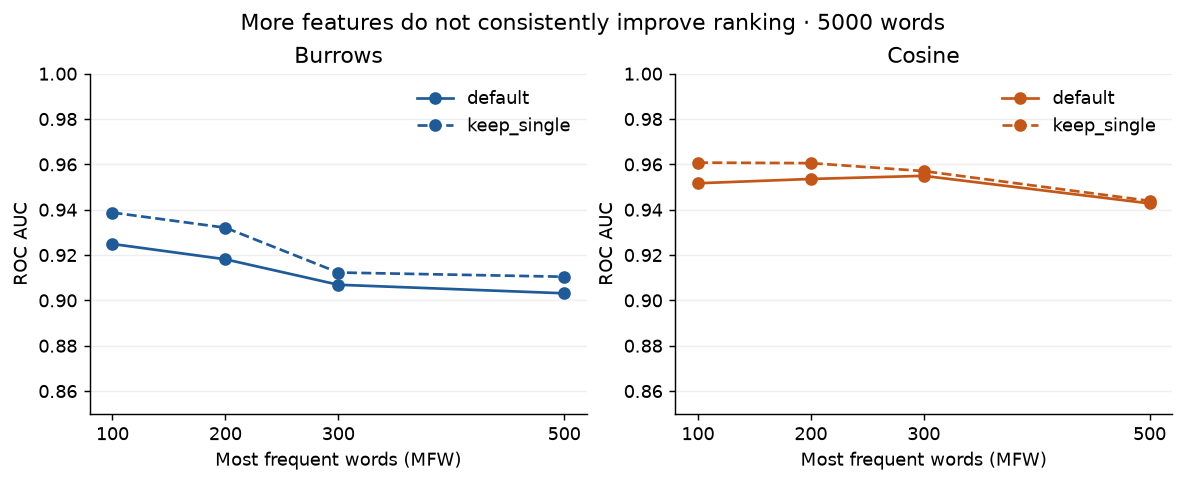

In [5]:
display(results.query("raw_words == 5000")[["variant", "mfw", "metric", "true_positive_rate",
       "false_positive_rate", "macro_author_tpr", "macro_author_pair_fpr", "roc_auc"]].round(4))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), constrained_layout=True)
for ax, metric in zip(axes, COLORS):
    for variant, style in [("default", "-"), ("keep_single", "--")]:
        subset = results.query("raw_words == 5000 and metric == @metric and variant == @variant").sort_values("mfw")
        ax.plot(subset.mfw, subset.roc_auc, marker="o", linestyle=style, color=COLORS[metric], label=variant)
    ax.set_title(metric.title())
    ax.set_xlabel("Most frequent words (MFW)")
    ax.set_ylabel("ROC AUC")
    ax.set_ylim(.85, 1)
    ax.set_xticks([100, 200, 300, 500])
    ax.legend(frameon=False)
    ax.grid(axis="y", alpha=.2)
fig.suptitle("More features do not consistently improve ranking · 5000 words")
fig.savefig(FIGURES / "features.png", bbox_inches="tight")
plt.show()

## Висновки й наступні досліди

1. Короткі тексти за строгого порога часто не виявляються як спільне авторство. Не можна перетворювати відсутність сигналу на твердження «автори різні».
2. Cosine — кандидат для подальшої перевірки; однолітерні слова та кількість ознак потребують незалежного підтвердження. Виробничі налаштування не змінено.
3. Лише сім авторів в оцінюванні; повторні уривки та пари залежні. Довірчі інтервали не оцінювалися. Жанр, епоха й тема можуть створювати додатковий сигнал.
4. Наступний крок — оцінити повний алгоритм із bootstrap, неоднакові довжини, тему/жанр та сучасні українські тексти з підтвердженим авторством. Числа цього досліду не слід подавати як точність методики DIMS на текстах моніторингу.